# Problems

## Loading Libraries and Dataset

### Libraries

In [13]:
# First, import libraries I believe will be necessary based on previous analysis (will change this as i go)
import pandas as pd
import numpy as np
import sklearn as sk
from sklearn import datasets
import matplotlib.pyplot as plt 
from sklearn.preprocessing import LabelEncoder as le
from sklearn.linear_model import LinearRegression
import seaborn as sns
import statistics
from scipy.stats import norm

### Load Iris dataset

In [2]:
#get the data from scikit-learn (see: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html#sklearn.datasets.load_iris)
# use frame=true to make it a dataframe
iris = sk.datasets.load_iris(as_frame=True)
iris_df = iris.frame

In [3]:
iris_df["species"] = iris_df["target"].map(dict(enumerate(iris.target_names)))


In [4]:
# return to show the structure and varaible names.
# https://www.w3schools.com/python/pandas/ref_df_head.asp#:~:text=The%20head()%20method%20returns,a%20number%20is%20not%20specified.&text=Note%3A%20The%20column%20names%20will,addition%20to%20the%20specified%20rows.
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## Problem 1: Exploring Petal Length

In this section, we will explore the distribution of petal length.

In [7]:
# Create separate dataframes for iris_setosa, iris_versicolor and iris_virginica by filtering the species column
iris_setosa = iris_df[iris_df['species']=='setosa'] # filter iris Setosa
iris_versicolor = iris_df[iris_df['species']=='versicolor'] # filter iris versicolor   
iris_virginica = iris_df[iris_df['species']=='virginica'] # filter iris virginica   


In [8]:
# print top 10 of each new subset of data
print(iris_setosa.head(10))
print(iris_versicolor.head(10))
print(iris_virginica.head(10)) 

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  
5       0 

In [9]:
print(iris_versicolor.head(10))

    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
50                7.0               3.2                4.7               1.4   
51                6.4               3.2                4.5               1.5   
52                6.9               3.1                4.9               1.5   
53                5.5               2.3                4.0               1.3   
54                6.5               2.8                4.6               1.5   
55                5.7               2.8                4.5               1.3   
56                6.3               3.3                4.7               1.6   
57                4.9               2.4                3.3               1.0   
58                6.6               2.9                4.6               1.3   
59                5.2               2.7                3.9               1.4   

    target     species  
50       1  versicolor  
51       1  versicolor  
52       1  versicolor  
53       1  versico

In [10]:
print(iris_virginica.head(10)) 

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
100                6.3               3.3                6.0               2.5   
101                5.8               2.7                5.1               1.9   
102                7.1               3.0                5.9               2.1   
103                6.3               2.9                5.6               1.8   
104                6.5               3.0                5.8               2.2   
105                7.6               3.0                6.6               2.1   
106                4.9               2.5                4.5               1.7   
107                7.3               2.9                6.3               1.8   
108                6.7               2.5                5.8               1.8   
109                7.2               3.6                6.1               2.5   

     target    species  
100       2  virginica  
101       2  virginica  
102       2  virginica  
103     

Next, we'll plot a histogram of petal length and impose a curve showing the normal distribution (first go, fix later!)

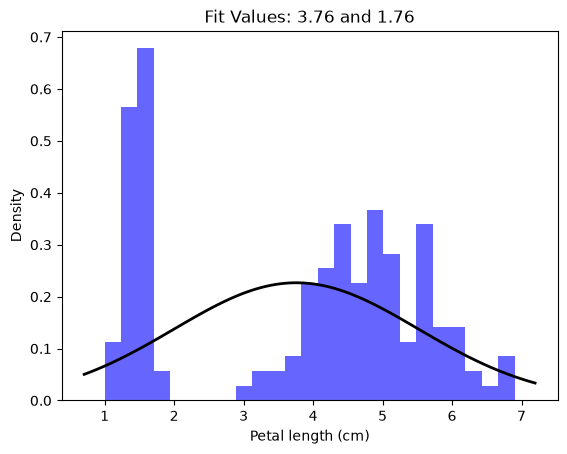

In [16]:
# code adapted from: https://www.geeksforgeeks.org/python/how-to-plot-normal-distribution-over-histogram-in-python/ 
data = iris_df["petal length (cm)"]

mu, std = norm.fit(data) 
plt.hist(data, bins=25, density=True, alpha=0.6, color='b')
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'k', linewidth=2)
title = "Fit Values: {:.2f} and {:.2f}".format(mu, std)
plt.title(title)
plt.xlabel("Petal length (cm)")
plt.ylabel("Density")

plt.show()